# 14 · Reading a plate by redrawing it: SPD-Conv reader

The YOLO26s reader is kept as it is. After it:

1. **Learned plate layout:** the reader's guesses are turned into the 5 best readings, scored by the reader and by how
   common their layout (digits, districts, letters, words) is in the training labels.
2. **Redrawing:** each reading is drawn as a clean plate, fitted to the photo (corners, brightness, blur), and the
   reading whose drawing fits best is chosen.

**Inputs:** the `bangla-plate-reading` dataset and the output of notebook 12 (SPD-Conv), the best reader on plate accuracy. Attach only that one `best.pt`.

In [3]:
%pip install -q ultralytics==8.4.46

Note: you may need to restart the kernel to use updated packages.


In [4]:
import json
from pathlib import Path

import pandas as pd
import torch
from ultralytics import YOLO

INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")

DATA = next(p for p in INPUT.rglob("bangla-plate-reading") if p.is_dir())
WEIGHTS = list(INPUT.rglob("best.pt"))
assert len(WEIGHTS) == 1, "attach only the reader-spd output (one best.pt)"
print(DATA)
print(WEIGHTS)

/kaggle/input/datasets/raahad/bangla-plate-reading
[PosixPath('/kaggle/input/models/raahad/reader-spd/pytorch/default/1/best.pt')]


## Custom layers

The readers from notebooks 10, 12 and 13 contain custom layers; this file lets any of them be loaded.

In [5]:
%%writefile /kaggle/working/plate_layers.py
import json
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import deform_conv2d
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.nn.modules import Conv
from ultralytics.nn.modules.block import Bottleneck
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils import RANK
import ultralytics.utils.torch_utils as torch_utils

KINDS = ["digit", "district", "letter", "word"]


# ---------------------------------------------------------------- deformable convolution (notebook 10)

class DConv(nn.Module):
    """Deformable 3x3 convolution (DCNv2) made from a pretrained Conv.

    The offsets start at zero and the mask at one, so before training it gives exactly the same output
    as the Conv it replaces; training then learns where each kernel tap should look.
    """

    def __init__(self, conv):
        super().__init__()
        c = conv.conv
        self.weight = nn.Parameter(c.weight.detach().clone())
        self.stride, self.padding, self.dilation = c.stride, c.padding, c.dilation
        taps = c.kernel_size[0] * c.kernel_size[1]
        self.offset = nn.Conv2d(c.in_channels, 3 * taps, c.kernel_size, c.stride, c.padding)
        nn.init.zeros_(self.offset.weight)
        nn.init.zeros_(self.offset.bias)
        self.bn = conv.bn
        self.act = conv.act

    def forward(self, x):
        dy_dx_1, dy_dx_2, mask = self.offset(x).chunk(3, dim=1)
        offset = torch.cat([dy_dx_1, dy_dx_2], dim=1)
        y = deform_conv2d(x, offset, self.weight, None, self.stride, self.padding, self.dilation, 2 * torch.sigmoid(mask))
        return self.act(self.bn(y))


# Ultralytics counts FLOPs with thop on an uninitialised tensor and the deformable op crashes on it.
# The count is only for the printed summary, so it is skipped for models with deformable convs.
_get_flops = torch_utils.get_flops


def _get_flops_safe(model, imgsz=640):
    if any(isinstance(m, DConv) for m in model.modules()):
        return 0.0
    return _get_flops(model, imgsz)


torch_utils.get_flops = _get_flops_safe


def add_dcn(model, layers=(6, 8)):
    """Swap the 3x3 conv of every bottleneck in backbone layers 6 and 8 (P4 and P5) for a DConv."""
    swapped = 0
    for i in layers:
        for m in model.model[i].modules():
            if isinstance(m, Bottleneck) and isinstance(m.cv2, Conv) and m.cv2.conv.kernel_size == (3, 3) \
                    and m.cv2.conv.stride == (1, 1) and m.cv2.conv.groups == 1:
                m.cv2 = DConv(m.cv2)
                swapped += 1
    return swapped


class DCNTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg, weights, verbose)
        print("deformable convs:", add_dcn(model))
        return model


# ---------------------------------------------------------------- SPD-Conv (notebook 12)

class SPDConv(nn.Module):
    """Space-to-depth then a stride-1 conv: halves the size without dropping any pixel (SPD-Conv)."""

    def __init__(self, c1, c2):
        super().__init__()
        self.conv = Conv(4 * c1, c2, 3, 1)

    def forward(self, x):
        x = torch.cat([x[..., ::2, ::2], x[..., 1::2, ::2], x[..., ::2, 1::2], x[..., 1::2, 1::2]], dim=1)
        return self.conv(x)


def add_spd(model, layers=(1, 3, 5, 7)):
    """Replace the stride-2 Conv layers of the backbone (the downsampling to P2, P3, P4 and P5) with SPDConv."""
    for i in layers:
        old = model.model[i]
        new = SPDConv(old.conv.in_channels, old.conv.out_channels)
        new.f, new.i, new.type = old.f, old.i, "SPDConv"
        new.np = sum(p.numel() for p in new.parameters())
        model.model[i] = new
    return len(layers)


class SPDTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg, weights, verbose)
        print("SPD layers:", add_spd(model))
        return model


# ---------------------------------------------------------------- layout head (notebook 13)

class Tap(nn.Module):
    """Wraps one backbone layer and keeps its last output, so the layout head can read it."""

    def __init__(self, m):
        super().__init__()
        self.m = m
        self.f, self.i, self.type, self.np = m.f, m.i, m.type, m.np
        self.out = None

    def forward(self, x):
        self.out = self.m(x)
        return self.out

    def __getstate__(self):
        state = self.__dict__.copy()
        state["out"] = None   # never save a feature map with the model
        return state


class LayoutHead(nn.Module):
    """Predicts how many digits, districts, letters and words the plate has, from pooled backbone features."""

    def __init__(self, c, caps, hidden=256):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(2 * c, hidden), nn.SiLU())
        self.heads = nn.ModuleList(nn.Linear(hidden, cap + 1) for cap in caps)

    def forward(self, x):
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], 1).flatten(1)
        h = self.fc(x)
        return [head(h) for head in self.heads]


def plate_layout_info(data_dir):
    """Kind of every class (0 digit, 1 district, 2 letter, 3 word) and the largest count of each kind in training."""
    data_dir = Path(data_dir)
    classes = json.loads((data_dir / "classes.json").read_text(encoding="utf-8"))
    kinds = [KINDS.index(c["kind"]) for c in classes]
    caps = [0, 0, 0, 0]
    for label in (data_dir / "labels" / "train").glob("*.txt"):
        counts = [0, 0, 0, 0]
        for line in label.read_text().splitlines():
            if line.strip():
                counts[kinds[int(line.split()[0])]] += 1
        caps = [max(a, b) for a, b in zip(caps, counts)]
    return kinds, caps


class LayoutModel(DetectionModel):
    """YOLO detector with an extra head that predicts the plate layout, trained together with detection."""

    def add_layout(self, kinds, caps, layer=10, weight=1.0):
        self.model[layer] = Tap(self.model[layer])
        self.layout_layer = layer
        self.layout_caps = list(caps)
        self.layout_weight = weight
        self.register_buffer("kind_index", torch.tensor(kinds, dtype=torch.long))
        with torch.no_grad():
            p = next(self.parameters())
            s = int(self.stride.max())
            self.model.eval()
            self.forward(torch.zeros(1, 3, 2 * s, 2 * s, device=p.device, dtype=p.dtype))
            self.model.train()
        c = self.model[layer].out.shape[1]
        self.model[layer].out = None
        self.layout_head = LayoutHead(c, caps)

    def layout_logits(self):
        return self.layout_head(self.model[self.layout_layer].out)

    def layout_targets(self, batch, n):
        counts = torch.zeros(n, 4, dtype=torch.long, device=self.kind_index.device)
        if len(batch["cls"]):
            img = batch["batch_idx"].long().to(counts.device)
            kind = self.kind_index[batch["cls"].view(-1).long().to(counts.device)]
            counts.index_put_((img, kind), torch.ones_like(img), accumulate=True)
        caps = torch.tensor(self.layout_caps, device=counts.device)
        return torch.minimum(counts, caps)

    def loss(self, batch, preds=None):
        if preds is None:
            preds = self.forward(batch["img"])
        det, items = super().loss(batch, preds)
        logits = self.layout_logits()
        self.model[self.layout_layer].out = None
        n = batch["img"].shape[0]
        target = self.layout_targets(batch, n)
        layout = sum(F.cross_entropy(l.float(), target[:, j]) for j, l in enumerate(logits))
        return torch.cat([det.view(-1), (self.layout_weight * layout * n).view(1)]), items


class LayoutTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = LayoutModel(cfg, nc=self.data["nc"], ch=self.data["channels"], verbose=verbose and RANK == -1)
        if weights:
            model.load(weights)
        kinds, caps = plate_layout_info(Path(self.args.data).parent)
        model.add_layout(kinds, caps)
        print("layout head: caps (digit, district, letter, word) =", caps)
        return model


def layout_probabilities(core, images, imgsz, device):
    """Layout probabilities per image from a trained LayoutModel: list of 4 arrays (one per kind) per image."""
    import cv2
    from ultralytics.data.augment import LetterBox

    box = LetterBox((imgsz, imgsz), auto=False)
    out = []
    core = core.to(device).float().eval()
    with torch.no_grad():
        for start in range(0, len(images), 64):
            batch = []
            for path in images[start:start + 64]:
                img = box(image=cv2.imread(str(path)))[:, :, ::-1].copy()
                batch.append(torch.from_numpy(img).permute(2, 0, 1).float() / 255)
            core(torch.stack(batch).to(device))
            probs = [p.softmax(1).cpu().numpy() for p in core.layout_logits()]
            core.model[core.layout_layer].out = None
            for k in range(len(batch)):
                out.append([p[k] for p in probs])
    return out

Writing /kaggle/working/plate_layers.py


In [6]:
import sys

sys.path.insert(0, str(WORK))
from plate_layers import KINDS as LAYER_KINDS, layout_probabilities

In [7]:
classes = json.loads((DATA / "classes.json").read_text(encoding="utf-8"))
bangla = [c["bangla"] for c in classes]
kind = [c["kind"] for c in classes]

test_images = sorted((DATA / "images" / "test").iterdir())
print(len(classes), "classes")
print(len(test_images), "test plates")

103 classes
778 test plates


## Plate text

Same as notebooks 05 and 06: district, word and letter from left to right, then the six digits as `xx-xxxx`.
The true text of a test plate comes from its label file.

In [8]:
def plate_text(chars):
    # chars: list of (class id, x centre)
    chars = sorted(chars, key=lambda c: c[1])
    head = " ".join(bangla[c] for c, x in chars if kind[c] != "digit")
    digits = "".join(bangla[c] for c, x in chars if kind[c] == "digit")
    if len(digits) == 6:
        digits = digits[:2] + "-" + digits[2:]
    return " ".join(part for part in [head, digits] if part)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


def read_labels(image_path, split="test"):
    # YOLO label file -> list of (class id, x centre, y centre, width, height)
    label = DATA / "labels" / split / (image_path.stem + ".txt")
    boxes = []
    for line in label.read_text().splitlines():
        p = line.split()
        if p:
            boxes.append((int(p[0]), *map(float, p[1:])))
    return boxes


def read_truth(image_path, split="test"):
    return plate_text([(b[0], b[1]) for b in read_labels(image_path, split)])


for path in test_images[:3]:
    print(path.name[:50], "->", read_truth(path))
print(edit_distance("ঢাকা মেট্রো গ ২৪-২৯৫৫", "ঢাকা মেট্রো ২৪-২৯৫৫"))

bd-lpr__110_78_1_jpg.rf.d7fe68d3205b26fe2a8f82ec74 -> ঢাকা মেট্রো ঘ ১৫-৮৭২৬
bd-lpr__112_218_1_jpg.rf.615e65a9b5abddc656237c528 -> ঢাকা মেট্রো ঘ ১১-৮৯২৫
bd-lpr__116_132_1_jpg.rf.e7262355591449bbae7d2b63c -> ঢাকা মেট্রো ঘ ১৭-১১৬২
2


## Baseline: current reader on the test set

The reader at 0.25 confidence, characters sorted left to right, as in the deployed AI service.
This must match notebook 05: 77.4% on all 939 plates (75.7% bd-lpr, 77.9% blpd).

In [9]:
reader = YOLO(WEIGHTS[0])
device = 0 if torch.cuda.is_available() else "cpu"

rows = []
for start in range(0, len(test_images), 64):
    batch = test_images[start:start + 64]
    results = reader.predict(batch, imgsz=320, conf=0.25, device=device, verbose=False)
    for path, r in zip(batch, results):
        chars = list(zip(r.boxes.cls.int().tolist(), r.boxes.xywhn[:, 0].tolist()))
        truth = read_truth(path)
        pred = plate_text(chars)
        rows.append({"image": path.name, "source": path.name.split("__")[0],
                     "truth": truth, "predicted": pred, "correct": truth == pred,
                     "errors": edit_distance(truth, pred), "length": len(truth)})

baseline = pd.DataFrame(rows)
baseline.head()

,image,source,truth,predicted,correct,errors,length
0,bd-lpr__110_78_1_jpg.rf.d7fe68d3205b26fe2a8f82...,bd-lpr,ঢাকা মেট্রো ঘ ১৫-৮৭২৬,ঢাকা মেট্রো ঘ ১৫-৮৭২৬,True,0,21
1,bd-lpr__112_218_1_jpg.rf.615e65a9b5abddc656237...,bd-lpr,ঢাকা মেট্রো ঘ ১১-৮৯২৫,ঢাকা মেট্রো ঘ ১১-৮৯২৫,True,0,21
2,bd-lpr__116_132_1_jpg.rf.e7262355591449bbae7d2...,bd-lpr,ঢাকা মেট্রো ঘ ১৭-১১৬২,ঢাকা মেট্রো ঘ ১৭-১১৬২,True,0,21
3,bd-lpr__118_25_1_jpg.rf.e7ca6f9923b292de362f75...,bd-lpr,ঢাকা মেট্রো ঘ ১৫-০৫১৯,ঢাকা মেট্রো ঘ ১৫-০৫১৯,True,0,21
4,bd-lpr__120_396_1_jpg.rf.2a6da539a86c906b3155f...,bd-lpr,ঢাকা মেট্রো গ ১৩-২০৯৪,ঢাকা মেট্রো গ ১৩-২০৯৪,True,0,21


In [10]:
def summary(df):
    return pd.Series({"plates": len(df),
                      "plate acc %": round(100 * df["correct"].mean(), 1),
                      "CER %": round(100 * df["errors"].sum() / df["length"].sum(), 2)})


table = baseline.groupby("source").apply(summary)
table.loc["all"] = summary(baseline)
table

/tmp/ipykernel_50/2729818310.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table = baseline.groupby("source").apply(summary)


,plates,plate acc %,CER %
source,,,
bd-lpr,218.0,82.1,2.25
blpd,560.0,83.4,5.96
all,778.0,83.0,4.85


## Plate rules: the 5 best valid readings

A Bangladeshi plate has one district, at most one word (Metro / Chatto / Raj), one series letter and six digits.

The reader is run again at 0.05 confidence so every character position keeps its weaker guesses too.
Guesses that overlap are one position. Each position either takes one of its (up to 3) guesses, scored `log(conf)`,
or is skipped as noise, scored `log(1 - best conf)`. A beam search keeps only readings that follow the plate pattern,
and the 5 best go to the redrawing step.

In [11]:
def reader_guesses(images, conf=0.05):
    out = {}
    for start in range(0, len(images), 64):
        batch = images[start:start + 64]
        results = reader.predict(batch, imgsz=320, conf=conf, device=device, max_det=100, verbose=False)
        for path, r in zip(batch, results):
            out[path.name] = [
                {"cls": c, "conf": p, "x": xywh[0], "box": xyxy}
                for c, p, xywh, xyxy in zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist(),
                                            r.boxes.xywhn.tolist(), r.boxes.xyxyn.tolist())
            ]
    return out


test_guesses = reader_guesses(test_images)
print(sum(len(g) for g in test_guesses.values()), "guesses on", len(test_guesses), "plates")

6848 guesses on 778 plates


In [12]:
import math

LIMIT = {"digit": 6, "district": 1, "letter": 1, "word": 1}
KINDS = list(LIMIT)


def iou(a, b):
    w = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union else 0.0


def positions(guesses):
    # overlapping guesses are one character position, best guess first
    groups = []
    for g in sorted(guesses, key=lambda g: -g["conf"]):
        for group in groups:
            if iou(group[0]["box"], g["box"]) > 0.5:
                group.append(g)
                break
        else:
            groups.append([g])
    return sorted(groups, key=lambda group: group[0]["x"])


def top_readings(guesses, k=5, beam=256):
    groups = positions(guesses)
    # a state is (score, counts per kind, chosen guesses)
    states = [(0.0, (0, 0, 0, 0), ())]
    for i, group in enumerate(groups):
        left = len(groups) - i - 1
        options = group[:3]
        new_states = []
        for score, counts, chosen in states:
            # skip this position
            new_states.append((score + math.log(max(1e-4, 1 - options[0]["conf"])), counts, chosen))
            # or take one of its guesses
            for g in options:
                j = KINDS.index(kind[g["cls"]])
                c = list(counts)
                c[j] += 1
                if c[j] <= LIMIT[KINDS[j]]:
                    new_states.append((score + math.log(max(1e-4, g["conf"])), tuple(c), chosen + (g,)))
        # drop states that can no longer reach six digits, a district and a letter
        new_states = [s for s in new_states if (6 - s[1][0]) + (1 - s[1][1]) + (1 - s[1][2]) <= left]
        states = sorted(new_states, key=lambda s: -s[0])[:beam]

    readings = {}
    for score, counts, chosen in states:
        if counts[:3] == (6, 1, 1):
            text = plate_text([(g["cls"], g["x"]) for g in chosen])
            if text not in readings or score > readings[text]["logp"]:
                readings[text] = {"text": text, "logp": score, "chars": [(g["cls"], g["box"]) for g in chosen]}
    return sorted(readings.values(), key=lambda r: -r["logp"])[:k]


example = test_images[0].name
for r in top_readings(test_guesses[example]):
    print(round(r["logp"], 2), r["text"])
print("truth:", read_truth(test_images[0]))

-0.16 ঢাকা মেট্রো ঘ ১৫-৮৭২৬
-4.55 ঢাকা ঘ ১৫-৮৭২৬
truth: ঢাকা মেট্রো ঘ ১৫-৮৭২৬


In [13]:
base_pred = dict(zip(baseline["image"], baseline["predicted"]))

rules = []
for path in test_images:
    readings = top_readings(test_guesses[path.name])
    truth = read_truth(path)
    # no valid reading: keep what the reader says today
    pred = readings[0]["text"] if readings else base_pred[path.name]
    rules.append({"image": path.name, "source": path.name.split("__")[0], "truth": truth,
                  "predicted": pred, "correct": truth == pred,
                  "errors": edit_distance(truth, pred), "length": len(truth),
                  "in_top5": any(r["text"] == truth for r in readings) or truth == pred,
                  "n_readings": len(readings)})
rules = pd.DataFrame(rules)

compare = pd.DataFrame({
    "baseline acc %": baseline.groupby("source")["correct"].mean() * 100,
    "plate rules acc %": rules.groupby("source")["correct"].mean() * 100,
    "truth in top 5 %": rules.groupby("source")["in_top5"].mean() * 100,
})
compare.loc["all"] = [baseline["correct"].mean() * 100, rules["correct"].mean() * 100, rules["in_top5"].mean() * 100]
print("plates with no valid reading (reader text kept):", (rules["n_readings"] == 0).sum())
print("CER %: baseline", round(100 * baseline["errors"].sum() / baseline["length"].sum(), 2),
      "| plate rules", round(100 * rules["errors"].sum() / rules["length"].sum(), 2))
compare.round(1)

plates with no valid reading (reader text kept): 77
CER %: baseline 4.85 | plate rules 3.74


,baseline acc %,plate rules acc %,truth in top 5 %
source,,,
bd-lpr,82.1,82.6,83.5
blpd,83.4,88.2,89.1
all,83.0,86.6,87.5


## Where the wrong plates are lost

Every plate the plate rules still get wrong is put in one group, checked in this order:

- **not the plate pattern**: the true label itself does not have one district, one letter and six digits
- **character not found**: a true character has no reader guess on it at all (even at 0.05)
- **right class not guessed**: the reader guessed something there, but never the right class
- **right class ranked lower**: the right class is among the guesses at that place, but a wrong one was chosen
- **other**: every character has the right class as its best guess, yet the text is wrong (an extra character, order)

In [14]:
def corners(box):
    x, y, w, h = box
    return [x - w / 2, y - h / 2, x + w / 2, y + h / 2]


def why_wrong(path):
    labels = read_labels(path)
    counts = {k: sum(kind[b[0]] == k for b in labels) for k in LIMIT}
    if (counts["digit"], counts["district"], counts["letter"]) != (6, 1, 1) or counts["word"] > 1:
        return "not the plate pattern"
    guesses = test_guesses[path.name]
    worst = "other"
    for cls, *box in labels:
        here = sorted([g for g in guesses if iou(g["box"], corners(box)) > 0.3], key=lambda g: -g["conf"])
        if not here:
            return "character not found"
        if cls not in [g["cls"] for g in here]:
            worst = "right class not guessed"
        elif here[0]["cls"] != cls and worst == "other":
            worst = "right class ranked lower"
    return worst


wrong = rules[~rules["correct"]].copy()
wrong["why"] = [why_wrong(DATA / "images" / "test" / name) for name in wrong["image"]]
print(len(wrong), "wrong plates out of", len(rules))
wrong.groupby(["why", "source"]).size().unstack(fill_value=0).assign(total=lambda d: d.sum(axis=1))

104 wrong plates out of 778


source,bd-lpr,blpd,total
why,,,
character not found,4,18,22
not the plate pattern,17,16,33
other,1,1,2
right class not guessed,15,27,42
right class ranked lower,1,4,5


In [15]:
for why, group in wrong.groupby("why"):
    print(why)
    print(group[["truth", "predicted"]].head(5).to_string(index=False))
    print()

character not found
                 truth           predicted
 হ ঢাকা মেট্রো ৫৯-৩১৮৮         মেট্রো ১৩১১
 ঢাকা মেট্রো খ ২৮-০৮৮৮ ঢাকা মেট্রো ২৮-০৮৮৮
 ঢাকা মেট্রো চ ১১-৫৪৮৫ ঢাকা মেট্রো ১১-৫৪৮৫
 ঢাকা মেট্রো গ ২৬-৫৫৯৬   ঢাকা মেট্রো ২৩৫৫১
খুলনা হ মেট্রো ১২-৩৫৭৯                 ১০১

not the plate pattern
              truth             predicted
ঢাকা মেট্রো ১৬-৩১৯০ ঢাকা মেট্রো হ ১৬-৩১৯০
ঢাকা মেট্রো ৩১-৪৬৯৪   ঢাকা মেট্রো ৩১-৪৬১৪
ঢাকা মেট্রো গ ২৯৬৮২ ঢাকা মেট্রো গ ২৯-৬০৮২
ঢাকা মেট্রো ২২-৭৯৪০ ঢাকা মেট্রো গ ২২-৭৯৪০
       ঢাকা ১১-৫৬৮৮             জ ১১-৫৬৮৮

other
                truth                   predicted
ঢাকা মেট্রো গ ৩৪-৭০৮৭              ঢাকা গ ৩৪-৭০৮৭
 হ মৌলভীবাজার ১১-৭৭৯৬ হ মৌলভীবাজার মেট্রো ১১-৭৭৯৬

right class not guessed
                truth             predicted
ঢাকা মেট্রো ড ১১-১১৯৭ ঢাকা মেট্রো ভ ১১-১১৯৭
ঢাকা মেট্রো ব ১৪-৭০৭১ ঢাকা মেট্রো ব ১৪-৭৩৭১
ট ঢাকা মেট্রো ১৬-০২২৫ ট ঢাকা মেট্রো ২৬-০২৯৫
ট ঢাকা মেট্রো ১৬-০২৯৫ ট ঢাকা মেট্রো ২৬-০২৯৫
ঢাকা মেট্রো গ ১৫-৩৭৪৭ ঢাকা মেট্রো গ ১৫-০৭৪৭



## Learned plate layout

The fixed rules above force exactly six digits, one district and one letter, so plates with another layout
(for example `ব ৫৭৩৮`, four digits and no district) can never be read. Here the layout is **learned from the training
labels** instead: every training plate is counted by its number of digits, districts, letters and words.

The search then allows any count up to the largest seen in training, and each reading gets
`score = reader log-probability + λ × log P(layout)`. Common layouts are preferred, rare ones are still possible,
and an unseen layout gets a small smoothed probability. `λ` is chosen on validation.

In [16]:
from collections import Counter

layout_counts = Counter()
for path in sorted((DATA / "images" / "train").iterdir()):
    labels = read_labels(path, "train")
    layout_counts[tuple(sum(kind[b[0]] == k for b in labels) for k in KINDS)] += 1

n_train = sum(layout_counts.values())
CAP = {k: max(layout[j] for layout in layout_counts) for j, k in enumerate(KINDS)}
n_possible = math.prod(CAP[k] + 1 for k in KINDS)


def layout_logp(counts):
    # add-0.5 smoothing over every layout within the caps
    return math.log((layout_counts.get(counts, 0) + 0.5) / (n_train + 0.5 * n_possible))


print(n_train, "training plates,", len(layout_counts), "different layouts, caps", CAP)
pd.DataFrame([{"digits": l[0], "districts": l[1], "letters": l[2], "words": l[3], "plates": n,
               "share %": round(100 * n / n_train, 2)} for l, n in layout_counts.most_common(12)])

6294 training plates, 25 different layouts, caps {'digit': 8, 'district': 1, 'letter': 2, 'word': 2}


,digits,districts,letters,words,plates,share %
0,6,1,1,1,3779,60.04
1,6,1,1,0,1902,30.22
2,6,1,0,1,192,3.05
3,6,0,1,2,188,2.99
4,6,0,1,0,119,1.89
5,2,1,1,0,19,0.30
6,4,0,1,0,12,0.19
7,3,1,0,1,12,0.19
8,4,1,1,0,9,0.14
9,0,1,1,0,9,0.14


In [17]:
import numpy as np


def top_readings_learned(guesses, lam, k=5, beam=256, prior=None):
    prior = prior or layout_logp
    groups = positions(guesses)
    states = [(0.0, (0, 0, 0, 0), ())]   # (score, counts per kind, chosen guesses)
    for group in groups:
        options = group[:3]
        new_states = []
        for score, counts, chosen in states:
            new_states.append((score + math.log(max(1e-4, 1 - options[0]["conf"])), counts, chosen))   # skip
            for g in options:
                j = KINDS.index(kind[g["cls"]])
                c = list(counts)
                c[j] += 1
                if c[j] <= CAP[KINDS[j]]:
                    new_states.append((score + math.log(max(1e-4, g["conf"])), tuple(c), chosen + (g,)))
        states = sorted(new_states, key=lambda s: -s[0])[:beam]

    readings = {}
    for score, counts, chosen in states:
        if not chosen:
            continue
        total = score + lam * prior(counts)
        text = plate_text([(g["cls"], g["x"]) for g in chosen])
        if text not in readings or total > readings[text]["logp"]:
            readings[text] = {"text": text, "logp": total, "layout": counts,
                              "chars": [(g["cls"], g["box"]) for g in chosen]}
    return sorted(readings.values(), key=lambda r: -r["logp"])[:k]


val_images = sorted((DATA / "images" / "val").iterdir())
val_guesses = reader_guesses(val_images)
val_truth = {p.name: read_truth(p, "val") for p in val_images}


def first_text(readings):
    return readings[0]["text"] if readings else ""


LAMBDAS = [0.25, 0.5, 1, 1.5, 2, 3, 5, 8]
val_acc = {lam: np.mean([first_text(top_readings_learned(val_guesses[n], lam)) == t for n, t in val_truth.items()])
           for lam in LAMBDAS}
best_lam = max(val_acc, key=val_acc.get)
for lam, a in val_acc.items():
    print(f"lambda {lam:>4}: validation plate accuracy {100 * a:.2f}%", "<- best" if lam == best_lam else "")

lambda 0.25: validation plate accuracy 86.60% 
lambda  0.5: validation plate accuracy 87.22% 
lambda    1: validation plate accuracy 87.57% 
lambda  1.5: validation plate accuracy 87.64% <- best
lambda    2: validation plate accuracy 87.43% 
lambda    3: validation plate accuracy 87.43% 
lambda    5: validation plate accuracy 87.22% 
lambda    8: validation plate accuracy 87.22% 


In [18]:
fixed_pred = dict(zip(rules["image"], rules["predicted"]))

learned = []
for path in test_images:
    readings = top_readings_learned(test_guesses[path.name], best_lam)
    truth = read_truth(path)
    pred = first_text(readings) or base_pred[path.name]
    learned.append({"image": path.name, "source": path.name.split("__")[0], "truth": truth, "predicted": pred,
                    "correct": truth == pred, "errors": edit_distance(truth, pred), "length": len(truth),
                    "in_top5": any(r["text"] == truth for r in readings) or truth == pred})
learned = pd.DataFrame(learned)


def acc_cer(df):
    return (round(100 * df["correct"].mean(), 1), round(100 * df["errors"].sum() / df["length"].sum(), 2))


rows = []
for name, df in [("baseline (today)", baseline), ("fixed plate rules", rules), ("learned layout", learned)]:
    for src in ["all"] + sorted(df["source"].unique()):
        part = df if src == "all" else df[df["source"] == src]
        a, c = acc_cer(part)
        rows.append({"method": name, "plates": src, "acc %": a, "CER %": c})
rows.append({"method": "learned layout: truth in top 5", "plates": "all",
             "acc %": round(100 * learned["in_top5"].mean(), 1), "CER %": None})
print(f"lambda = {best_lam}")
pd.DataFrame(rows).pivot(index="method", columns="plates", values="acc %")

lambda = 1.5


plates,all,bd-lpr,blpd
method,,,
baseline (today),83.0,82.1,83.4
fixed plate rules,86.6,82.6,88.2
learned layout,87.4,83.5,88.9
learned layout: truth in top 5,90.0,NaN,NaN


In [19]:
# plates the fixed rules could not read because their layout is not 6 digits / 1 district / 1 letter
other_layout = wrong[wrong["why"] == "not the plate pattern"]["image"]
check = learned.set_index("image").loc[other_layout, ["truth", "predicted", "correct"]]
print(f"{check['correct'].sum()} of {len(check)} 'not the plate pattern' plates are now read correctly")
print(check.head(10).to_string(index=False))

# from here on the redraw step works on the learned readings
fixed_top_readings = top_readings
top_readings = lambda guesses, k=5: top_readings_learned(guesses, best_lam, k)


def readings_for(name, guesses):
    return top_readings_learned(guesses, best_lam)

5 of 33 'not the plate pattern' plates are now read correctly
              truth             predicted  correct
ঢাকা মেট্রো ১৬-৩১৯০ ঢাকা মেট্রো হ ১৬-৩১৯০    False
ঢাকা মেট্রো ৩১-৪৬৯৪   ঢাকা মেট্রো ৩১-৪৬১৪    False
ঢাকা মেট্রো গ ২৯৬৮২ ঢাকা মেট্রো গ ২৯-৬০৮২    False
ঢাকা মেট্রো ২২-৭৯৪০ ঢাকা মেট্রো গ ২২-৭৯৪০    False
       ঢাকা ১১-৫৬৮৮             জ ১১-৫৬৮৮    False
             ব ৫৭৩৮                  ৫৭৮৮    False
ঢাকা মেট্রো ১১-৭৮৪৪ ঢাকা মেট্রো ট ১১-৭৮৪৪    False
ঢাকা মেট্রো ১৫-০৪১৪ ঢাকা মেট্রো ঘ ১৫-০৪১৪    False
ঢাকা মেট্রো ১৩-৯৯০৯ ঢাকা মেট্রো ঘ ১৩-৯৯০৯    False
ঢাকা মেট্রো ৩২-৮৫৬৫ ঢাকা মেট্রো গ ৩২-৮৫৬৫    False


## Learned layout from the layout head

Only for a reader trained with the layout head (notebook 13). Instead of one table of layout counts for all plates,
the head predicts the layout of **each plate**, and a reading is scored by
`reader log-probability + λ × log P(layout | this plate)`. `λ` is chosen on validation. If the head is better on
validation than the counted layout, the redraw step uses it.

In [20]:
core = YOLO(WEIGHTS[0]).model
HAS_HEAD = hasattr(core, "layout_head")
print("reader has a layout head:", HAS_HEAD)

if HAS_HEAD:
    head_images = val_images + test_images
    head_probs = dict(zip([p.name for p in head_images],
                          layout_probabilities(core, head_images, 320, device_t if "device_t" in globals() else
                                               ("cuda:0" if torch.cuda.is_available() else "cpu"))))

    def head_prior(name):
        p = head_probs[name]
        def prior(counts):
            return sum(math.log(max(1e-6, float(p[j][c]))) if c < len(p[j]) else math.log(1e-6)
                       for j, c in enumerate(counts))
        return prior

    head_acc = {lam: np.mean([first_text(top_readings_learned(val_guesses[n], lam, prior=head_prior(n))) == t
                              for n, t in val_truth.items()]) for lam in LAMBDAS}
    head_lam = max(head_acc, key=head_acc.get)
    for lam, a in head_acc.items():
        print(f"lambda {lam:>4}: validation plate accuracy {100 * a:.2f}%", "<- best" if lam == head_lam else "")

    head_rows = []
    for path in test_images:
        readings = top_readings_learned(test_guesses[path.name], head_lam, prior=head_prior(path.name))
        truth = read_truth(path)
        pred = first_text(readings) or base_pred[path.name]
        head_rows.append({"image": path.name, "source": path.name.split("__")[0], "truth": truth, "predicted": pred,
                          "correct": truth == pred, "errors": edit_distance(truth, pred), "length": len(truth)})
    head_layout = pd.DataFrame(head_rows)

    rows = []
    for name, df in [("baseline (today)", baseline), ("fixed plate rules", rules),
                     ("learned layout (counts)", learned), ("learned layout (head)", head_layout)]:
        for src in ["all"] + sorted(df["source"].unique()):
            part = df if src == "all" else df[df["source"] == src]
            a, c = acc_cer(part)
            rows.append({"method": name, "plates": src, "acc %": a, "CER %": c})
    display(pd.DataFrame(rows).pivot(index="method", columns="plates", values="acc %"))

    if max(head_acc.values()) > val_acc[best_lam]:
        print("the head is better on validation: the redraw step uses it")

        def readings_for(name, guesses):
            return top_readings_learned(guesses, head_lam, prior=head_prior(name))

reader has a layout head: False


## Glyph atlas

To draw a plate we need one clean image per character class. For each class we cut its boxes out of the training crops,
keep the 40 tallest (the sharpest), and take their pixel-wise median. No network is trained here.

Every crop is first turned grey, its contrast stretched to 0–1, and flipped if needed so the ink is dark on a light plate.

In [21]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

PH, PW = 80, 160   # every plate is compared at this size
GLYPH = 48         # size of one atlas image
PAD = 0.08         # margin around a character box, the same when cutting and drawing


def stretch(gray):
    lo, hi = np.percentile(gray, [2, 98])
    return np.clip((gray - lo) / max(hi - lo, 1e-3), 0, 1).astype(np.float32)


def normalise(gray):
    # contrast 0-1, ink dark on a light plate. The light/dark decision uses only the middle of the crop,
    # because many crops have a thick black frame around the plate.
    g = stretch(gray)
    h, w = g.shape
    middle = g[int(0.2 * h):int(0.8 * h), int(0.15 * w):int(0.85 * w)]
    if np.median(middle) < 0.5:
        g = 1 - g
    return g


def load_plate(path):
    # returns the normalised crop at full size and at the compare size
    full = normalise(np.asarray(Image.open(path).convert("L"), np.float32) / 255)
    small = Image.fromarray((full * 255).astype(np.uint8)).resize((PW, PH), Image.BILINEAR)
    return full, np.asarray(small, np.float32) / 255


def to_corners(box):
    # YOLO (x centre, y centre, w, h) -> (x0, y0, x1, y1), all relative to the crop
    x, y, w, h = box
    return (x - w / 2, y - h / 2, x + w / 2, y + h / 2)


def padded(box):
    x0, y0, x1, y1 = box
    dx, dy = (x1 - x0) * PAD, (y1 - y0) * PAD
    return (x0 - dx, y0 - dy, x1 + dx, y1 + dy)


def resize(img, w, h):
    return np.asarray(Image.fromarray((img * 255).astype(np.uint8)).resize((w, h), Image.BILINEAR), np.float32) / 255


def clean_glyph(patch):
    # one character: own contrast, ink dark (ink is the smaller part of a character box), ink centred
    g = stretch(patch)
    if g.mean() < 0.5:
        g = 1 - g
    g = resize(g, GLYPH, GLYPH)
    ink = 1 - g
    if ink.sum() > 0:
        ys, xs = np.indices(ink.shape)
        dy = int(round(GLYPH / 2 - (ys * ink).sum() / ink.sum()))
        dx = int(round(GLYPH / 2 - (xs * ink).sum() / ink.sum()))
        shifted = np.ones_like(g)
        src = g[max(0, -dy):GLYPH - max(0, dy), max(0, -dx):GLYPH - max(0, dx)]
        shifted[max(0, dy):max(0, dy) + src.shape[0], max(0, dx):max(0, dx) + src.shape[1]] = src
        g = shifted
    return g


def sharpness(g):
    # variance of the Laplacian: higher is sharper
    lap = g[1:-1, 1:-1] * 4 - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    return float(lap.var())

In [22]:
from collections import defaultdict

train_images = sorted((DATA / "images" / "train").iterdir())
pool = defaultdict(list)   # class -> [(sharpness, glyph image)]

for path in train_images:
    gray = np.asarray(Image.open(path).convert("L"), np.float32) / 255
    h, w = gray.shape
    for cls, *box in read_labels(path, "train"):
        if len(pool[cls]) >= 400:
            continue
        x0, y0, x1, y1 = padded(to_corners(box))
        x0, x1 = int(max(0, x0 * w)), int(min(w, x1 * w))
        y0, y1 = int(max(0, y0 * h)), int(min(h, y1 * h))
        if x1 - x0 >= 8 and y1 - y0 >= 12:   # skip tiny characters
            g = clean_glyph(gray[y0:y1, x0:x1])
            pool[cls].append((sharpness(g), g))

atlas = {}
for cls, items in pool.items():
    items.sort(key=lambda t: -t[0])
    median = np.median(np.stack([g for _, g in items[:40]]), axis=0)
    # final stretch so the background is pure white and the ink black
    lo, hi = np.percentile(median, [3, 85])
    atlas[cls] = np.clip((median - lo) / max(hi - lo, 1e-3), 0, 1).astype(np.float32)

missing = [classes[c]["name"] for c in range(len(classes)) if c not in atlas]
print(len(train_images), "training crops")
print(len(atlas), "of", len(classes), "classes in the atlas, missing:", missing or "none")
np.savez_compressed(WORK / "glyph_atlas.npz", **{str(c): g for c, g in atlas.items()})

6294 training crops
102 of 103 classes in the atlas, missing: ['Nowabganj']


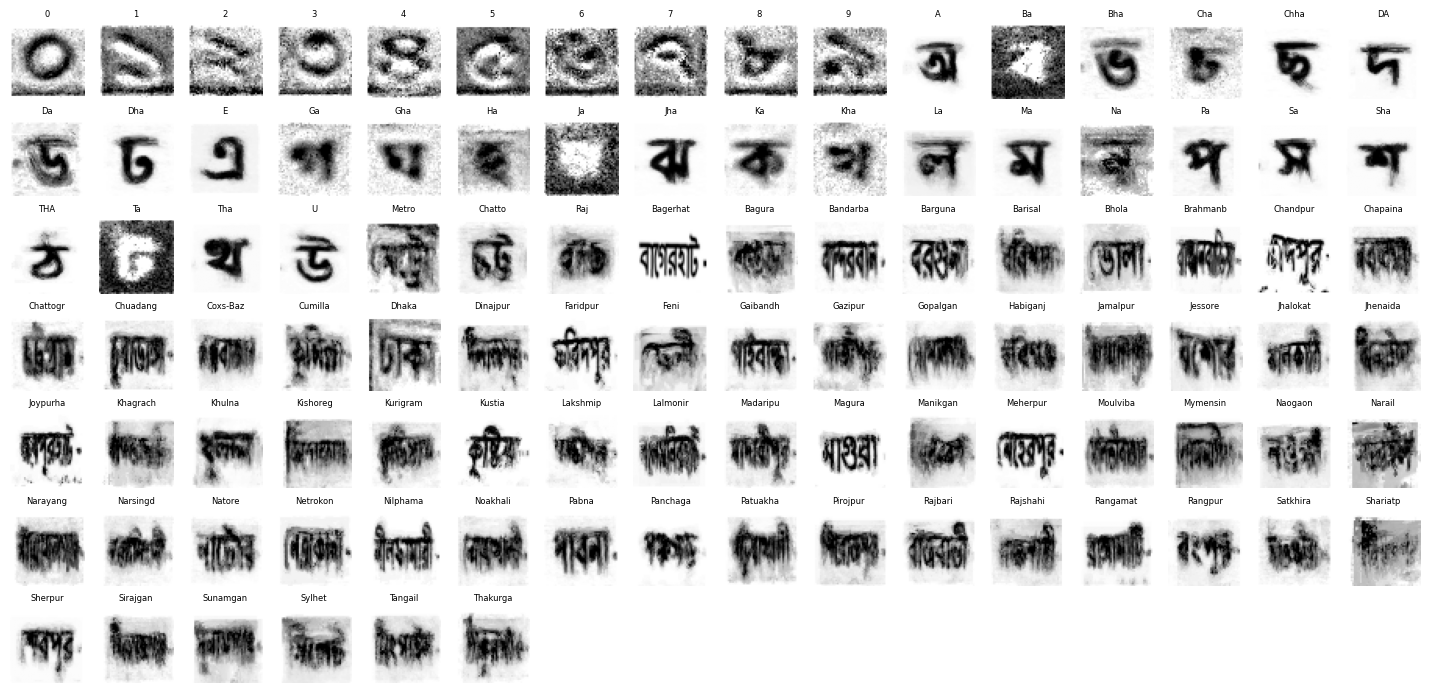

In [23]:
cols = 16
rows = math.ceil(len(atlas) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 0.9, rows))
for ax in axes.flat:
    ax.axis("off")
for ax, cls in zip(axes.flat, sorted(atlas)):
    ax.imshow(atlas[cls], cmap="gray", vmin=0, vmax=1)
    ax.set_title(classes[cls]["name"][:8], fontsize=6)
plt.tight_layout()
plt.savefig(WORK / "atlas.png", dpi=130)
plt.show()

## Drawing a plate

A reading is drawn on a white plate: each character's atlas image is pasted into its box, and a dash is drawn between the
second and third digit. Below, test plates drawn from their **true** labels next to the photo, to check the atlas looks right.

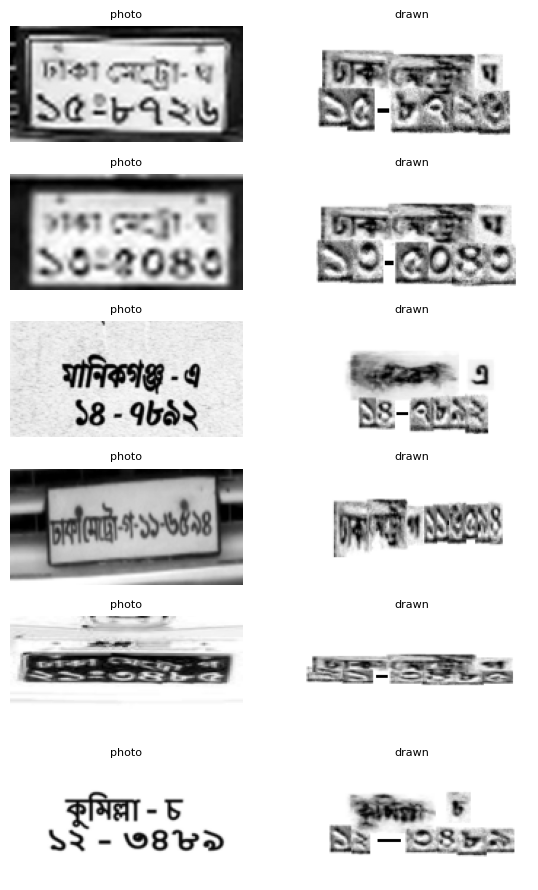

In [24]:
def draw_plate(chars):
    # chars: list of (class id, (x0, y0, x1, y1)) relative to the crop
    plate = np.ones((PH, PW), np.float32)
    for cls, box in chars:
        if cls not in atlas:
            continue
        x0, y0, x1, y1 = padded(box)
        px0, px1 = round(x0 * PW), round(x1 * PW)
        py0, py1 = round(y0 * PH), round(y1 * PH)
        if px1 - px0 < 2 or py1 - py0 < 2:
            continue
        glyph = resize(atlas[cls], px1 - px0, py1 - py0)
        # clip to the plate edges
        cx0, cy0, cx1, cy1 = max(px0, 0), max(py0, 0), min(px1, PW), min(py1, PH)
        if cx1 > cx0 and cy1 > cy0:
            part = glyph[cy0 - py0:cy1 - py0, cx0 - px0:cx1 - px0]
            plate[cy0:cy1, cx0:cx1] = np.minimum(plate[cy0:cy1, cx0:cx1], part)

    digits = sorted([box for cls, box in chars if kind[cls] == "digit"])
    if len(digits) == 6 and digits[2][0] > digits[1][2]:
        left, right = digits[1][2], digits[2][0]
        yc = np.mean([(b[1] + b[3]) / 2 for b in digits])
        dh = np.mean([b[3] - b[1] for b in digits])
        x0, x1 = round((left + 0.2 * (right - left)) * PW), round((right - 0.2 * (right - left)) * PW)
        y0 = round((yc - 0.06 * dh) * PH)
        plate[max(y0, 0):max(y0 + 1, round((yc + 0.06 * dh) * PH)), max(x0, 0):x1] = 0.0
    return plate


fig, axes = plt.subplots(6, 2, figsize=(6, 9))
for row, path in zip(axes, test_images[::len(test_images) // 6]):
    _, photo = load_plate(path)
    truth_chars = [(cls, to_corners(box)) for cls, *box in read_labels(path)]
    row[0].imshow(photo, cmap="gray", vmin=0, vmax=1)
    row[0].set_title("photo", fontsize=8)
    row[1].imshow(draw_plate(truth_chars), cmap="gray", vmin=0, vmax=1)
    row[1].set_title("drawn", fontsize=8)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.savefig(WORK / "drawn_vs_photo.png", dpi=130)
plt.show()

## Fitting a drawing to the photo

A drawing is moved onto the photo with three steps, all written in PyTorch so they can be adjusted by gradient descent:

1. **Warp:** the 4 corners of the drawing are moved (a perspective transform), which handles tilt.
2. **Blur:** a Gaussian blur with its own sigma, which handles out-of-focus and motion blur.
3. **Light:** a gain and a bias on the grey values, which handles dark plates.

The drawing is compared with the photo either by **pixels** or by **edges** (Sobel), which ignores dirt and uneven light.
All readings of a plate are fitted together as one batch.

In [25]:
import torch.nn.functional as F

device_t = "cuda" if torch.cuda.is_available() else "cpu"


def homography(src, dst):
    # (B, 4, 2) point pairs -> (B, 3, 3) matrices that map src to dst
    rows, rhs = [], []
    for i in range(4):
        x, y = src[:, i, 0], src[:, i, 1]
        u, v = dst[:, i, 0], dst[:, i, 1]
        one, zero = torch.ones_like(x), torch.zeros_like(x)
        rows.append(torch.stack([x, y, one, zero, zero, zero, -u * x, -u * y], -1))
        rows.append(torch.stack([zero, zero, zero, x, y, one, -v * x, -v * y], -1))
        rhs += [u, v]
    h = torch.linalg.solve(torch.stack(rows, 1), torch.stack(rhs, 1))
    return torch.cat([h, torch.ones_like(h[:, :1])], 1).view(-1, 3, 3)


def warp(img, offsets):
    # move the 4 corners of each image by offsets (B, 4, 2), in [-1, 1] units
    b, _, h, w = img.shape
    corners = torch.tensor([[-1., -1.], [1., -1.], [1., 1.], [-1., 1.]], device=img.device).expand(b, 4, 2)
    m = homography(corners + offsets, corners)   # output pixel -> drawing pixel
    ys = torch.linspace(-1 + 1 / h, 1 - 1 / h, h, device=img.device)
    xs = torch.linspace(-1 + 1 / w, 1 - 1 / w, w, device=img.device)
    gy, gx = torch.meshgrid(ys, xs, indexing="ij")
    pts = torch.stack([gx, gy, torch.ones_like(gx)], -1).view(1, -1, 3).expand(b, -1, 3)
    src = pts @ m.transpose(1, 2)
    grid = (src[..., :2] / src[..., 2:].clamp(min=1e-6)).view(b, h, w, 2)
    return F.grid_sample(img, grid, padding_mode="border", align_corners=False)


def blur(img, sigma):
    # Gaussian blur with one sigma per image
    b, _, h, w = img.shape
    r = torch.arange(-4, 5, device=img.device, dtype=img.dtype)
    k = torch.exp(-(r.view(1, -1) ** 2) / (2 * sigma.view(-1, 1) ** 2))
    k = k / k.sum(1, keepdim=True)
    x = img.view(1, b, h, w)
    x = F.conv2d(F.pad(x, (4, 4, 0, 0), mode="replicate"), k.view(b, 1, 1, 9), groups=b)
    x = F.conv2d(F.pad(x, (0, 0, 4, 4), mode="replicate"), k.view(b, 1, 9, 1), groups=b)
    return x.view(b, 1, h, w)


SOBEL = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)


def edges(img):
    s = SOBEL.to(img.device)
    p = F.pad(img, (1, 1, 1, 1), mode="replicate")
    e = torch.sqrt(F.conv2d(p, s) ** 2 + F.conv2d(p, s.transpose(2, 3)) ** 2 + 1e-6)
    return e / (e.mean((1, 2, 3), keepdim=True) + 1e-6)


def match_light(x, photo):
    # best gain and bias in closed form, so x has the photo's grey values
    xm, pm = x.mean((1, 2, 3), keepdim=True), photo.mean((1, 2, 3), keepdim=True)
    a = ((x - xm) * (photo - pm)).mean((1, 2, 3), keepdim=True) / (((x - xm) ** 2).mean((1, 2, 3), keepdim=True) + 1e-6)
    return a * x + (pm - a * xm)

In [26]:
STEPS = 40
REG = 0.5   # keeps the corners close to where the reader put the characters


def fit(drawings, photo, mode="edge", steps=STEPS):
    # drawings (k, 1, H, W), photo (1, 1, H, W) -> fitted drawings and one distance per drawing
    k = len(drawings)
    target = photo.expand(k, -1, -1, -1)
    if mode == "edge":
        target = edges(target)

    offsets = torch.zeros(k, 4, 2, device=drawings.device, requires_grad=True)
    gain = torch.ones(k, 1, 1, 1, device=drawings.device, requires_grad=True)
    bias = torch.zeros(k, 1, 1, 1, device=drawings.device, requires_grad=True)
    s = torch.full((k,), -0.5, device=drawings.device, requires_grad=True)   # sigma = softplus(s) + 0.3
    opt = torch.optim.Adam([{"params": [offsets], "lr": 0.01}, {"params": [gain, bias, s], "lr": 0.05}])

    for _ in range(steps):
        out = gain * blur(warp(drawings, offsets), F.softplus(s) + 0.3) + bias
        diff = (edges(out) if mode == "edge" else out) - target
        loss = diff.abs().mean((1, 2, 3)).sum() + REG * (offsets ** 2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        out = match_light(blur(warp(drawings, offsets), F.softplus(s) + 0.3), photo.expand(k, -1, -1, -1))
        diff = (edges(out) if mode == "edge" else out) - target
        dist = diff.abs().mean((1, 2, 3))
    return out, dist

### One plate

A test plate where the plate rules picked the wrong reading but the right one is among its 5 readings.
Each reading is drawn, fitted, and its distance to the photo printed. The right reading should have the smallest distance.

7 test plates: rules wrong, truth in top 5

pixel
  0.266  logp  -1.77  ঢাকা মেট্রো গ ৩৪-৭০৮৭ <- truth
  0.269  logp  -2.59  ঢাকা গ ৩৪-৭০৮৭ 
  0.265  logp  -9.48  ঢাকা মেট্রো ৩৪-৭০৮৭ 
  0.269  logp -10.69  গ ৩৪-৭০৮৭ 
  0.268  logp -14.91  ঢাকা ৩৪-৭০৮৭ 

edge
  1.010  logp  -1.77  ঢাকা মেট্রো গ ৩৪-৭০৮৭ <- truth
  1.062  logp  -2.59  ঢাকা গ ৩৪-৭০৮৭ 
  1.023  logp  -9.48  ঢাকা মেট্রো ৩৪-৭০৮৭ 
  1.134  logp -10.69  গ ৩৪-৭০৮৭ 
  1.102  logp -14.91  ঢাকা ৩৪-৭০৮৭ 


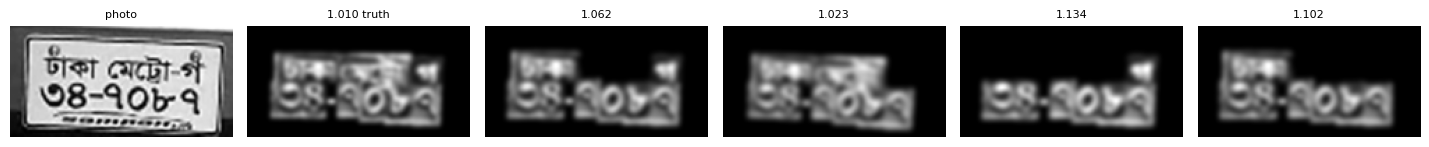

In [27]:
def fit_plate(path, mode="edge"):
    readings = top_readings(test_guesses[path.name])
    drawings = torch.from_numpy(np.stack([draw_plate(r["chars"]) for r in readings])).unsqueeze(1).to(device_t)
    _, photo = load_plate(path)
    photo = torch.from_numpy(photo).view(1, 1, PH, PW).to(device_t)
    fitted, dist = fit(drawings, photo, mode)
    return readings, photo, fitted, dist


wrong_but_close = rules[(~rules["correct"]) & rules["in_top5"]]
print(len(wrong_but_close), "test plates: rules wrong, truth in top 5")

path = DATA / "images" / "test" / wrong_but_close.iloc[0]["image"]
truth = read_truth(path)
for mode in ["pixel", "edge"]:
    readings, photo, fitted, dist = fit_plate(path, mode)
    print(f"\n{mode}")
    for r, d in zip(readings, dist.tolist()):
        print(f"  {d:.3f}  logp {r['logp']:6.2f}  {r['text']}", "<- truth" if r["text"] == truth else "")

fig, axes = plt.subplots(1, len(readings) + 1, figsize=(2.4 * (len(readings) + 1), 1.6))
axes[0].imshow(photo[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("photo", fontsize=8)
for ax, img, d, r in zip(axes[1:], fitted, dist.tolist(), readings):
    ax.imshow(img[0].cpu(), cmap="gray")
    ax.set_title(f"{d:.3f}" + (" truth" if r["text"] == truth else ""), fontsize=8)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fit every validation and test plate

The validation plates are used only to choose the weight between the reader's score and the fit distance.
For each plate, all its readings are drawn and fitted twice: with pixels and with edges.

In [28]:
import time

val_images = sorted((DATA / "images" / "val").iterdir())
val_guesses = reader_guesses(val_images)


def fit_split(images, guesses, keep_fitted=False):
    plates = []
    for path in images:
        readings = readings_for(path.name, guesses[path.name])
        plate = {"image": path.name, "path": path, "readings": readings}
        if readings:
            drawings = torch.from_numpy(np.stack([draw_plate(r["chars"]) for r in readings])).unsqueeze(1).to(device_t)
            _, photo = load_plate(path)
            photo = torch.from_numpy(photo).view(1, 1, PH, PW).to(device_t)
            _, d_pixel = fit(drawings, photo, "pixel")
            fitted, d_edge = fit(drawings, photo, "edge")
            for r, a, b in zip(readings, d_pixel.tolist(), d_edge.tolist()):
                r["dist"] = {"pixel": a, "edge": b}
            plate["photo"] = photo
            plate["fitted"] = fitted   # edge fit, used by the next two comparisons
        plates.append(plate)
    return plates


t0 = time.time()
val_plates = fit_split(val_images, val_guesses)
test_plates = fit_split(test_images, test_guesses)
ms = 1000 * (time.time() - t0) / (len(val_plates) + len(test_plates))
print(len(val_plates), "val plates,", len(test_plates), "test plates")
print(f"{ms:.1f} ms per plate to draw and fit its readings twice")

1448 val plates, 778 test plates
503.7 ms per plate to draw and fit its readings twice


## Comparing with the reader's own features

A third way to compare: pass the fitted drawing and the photo through the first layers of the YOLO26s reader
(up to stride 8) and take the cosine distance. No training.

In [29]:
backbone = YOLO(WEIGHTS[0]).model.to(device_t).float().eval()
FEAT_LAYER = 4


def reader_features(x):
    x = F.interpolate(x.repeat(1, 3, 1, 1), size=(96, 192), mode="bilinear", align_corners=False)
    for i, layer in enumerate(backbone.model):
        if layer.f != -1 or i > FEAT_LAYER:
            break
        x = layer(x)
    return F.normalize(x.flatten(1), dim=1)


with torch.no_grad():
    for plate in val_plates + test_plates:
        if plate["readings"]:
            d = 1 - (reader_features(plate["fitted"]) @ reader_features(plate["photo"]).T).squeeze(1)
            for r, v in zip(plate["readings"], d.tolist()):
                r["dist"]["feature"] = v
print("done")

done


## A learned comparison

A small encoder (about 1 M parameters) is trained so that a photo and the drawing of its own text land close together,
and drawings with one or two wrong characters land further away. Training pairs come for free: each training crop and
its label drawn with the atlas. The drawings get a random small warp, blur and light change so they look like photos.

In [30]:
import random
import torch.nn as nn


class PlateEncoder(nn.Module):
    def __init__(self, dim=128):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, 2, 1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, 1, 1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.net = nn.Sequential(block(1, 32), block(32, 64), block(64, 96), block(96, 128))   # 80x160 -> 5x10
        self.head = nn.Linear(128 * 5 * 10, dim)

    def forward(self, x):
        return F.normalize(self.head(self.net(x).flatten(1)), dim=1)


by_kind = defaultdict(list)
for c, k in enumerate(kind):
    by_kind[k].append(c)


def wrong_reading(chars, rng):
    # same boxes, one or two characters swapped for another class of the same kind
    chars = list(chars)
    for i in rng.sample(range(len(chars)), k=min(len(chars), rng.choice([1, 1, 2]))):
        cls, box = chars[i]
        others = [c for c in by_kind[kind[cls]] if c != cls and c in atlas]
        if others:
            chars[i] = (rng.choice(others), box)
    return chars


def camera_like(drawings):
    b = len(drawings)
    with torch.no_grad():
        x = warp(drawings, torch.randn(b, 4, 2, device=drawings.device) * 0.03)
        x = blur(x, torch.rand(b, device=drawings.device) * 1.2 + 0.3)
        x = x * (0.6 + 0.6 * torch.rand(b, 1, 1, 1, device=drawings.device)) + 0.2 * (torch.rand(b, 1, 1, 1, device=drawings.device) - 0.5)
    return x.clamp(0, 1)


train_photos, train_chars = [], []
for path in train_images:
    chars = [(cls, to_corners(box)) for cls, *box in read_labels(path, "train")]
    if chars:
        train_photos.append((load_plate(path)[1] * 255).astype(np.uint8))
        train_chars.append(chars)
train_photos = np.stack(train_photos)
print(len(train_photos), "training plates for the encoder")

6294 training plates for the encoder


In [31]:
EPOCHS, BATCH, NEG = 12, 64, 4
rng = random.Random(0)
torch.manual_seed(0)

encoder = PlateEncoder().to(device_t)
opt = torch.optim.AdamW(encoder.parameters(), lr=2e-3, weight_decay=1e-4)
steps = EPOCHS * (len(train_photos) // BATCH)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps)

t0 = time.time()
for epoch in range(EPOCHS):
    order = list(range(len(train_photos)))
    rng.shuffle(order)
    total, right, seen = 0.0, 0, 0
    for s in range(0, len(order) - BATCH + 1, BATCH):
        idx = order[s:s + BATCH]
        drawings = []
        for i in idx:
            drawings.append(draw_plate(train_chars[i]))                                   # own text
            drawings += [draw_plate(wrong_reading(train_chars[i], rng)) for _ in range(NEG)]   # wrong texts
        d = camera_like(torch.from_numpy(np.stack(drawings)).unsqueeze(1).to(device_t))
        p = torch.from_numpy(train_photos[idx]).float().div(255).unsqueeze(1).to(device_t)

        zp = encoder(p)
        zd = encoder(d).view(len(idx), NEG + 1, -1)
        logits = (zd @ zp.unsqueeze(2)).squeeze(2) / 0.1
        loss = F.cross_entropy(logits, torch.zeros(len(idx), dtype=torch.long, device=device_t))
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()

        total += loss.item() * len(idx)
        right += (logits.argmax(1) == 0).sum().item()
        seen += len(idx)
    print(f"epoch {epoch + 1:2d}  loss {total / seen:.3f}  picks its own drawing {100 * right / seen:.1f}%")

encoder.eval()
torch.save(encoder.state_dict(), WORK / "plate_encoder.pt")
print(f"{(time.time() - t0) / 60:.1f} min")

epoch  1  loss 1.606  picks its own drawing 20.8%
epoch  2  loss 1.532  picks its own drawing 24.7%
epoch  3  loss 1.468  picks its own drawing 27.4%
epoch  4  loss 1.403  picks its own drawing 30.3%
epoch  5  loss 1.295  picks its own drawing 38.1%
epoch  6  loss 1.124  picks its own drawing 48.8%
epoch  7  loss 1.013  picks its own drawing 55.8%
epoch  8  loss 0.931  picks its own drawing 60.1%
epoch  9  loss 0.850  picks its own drawing 64.9%
epoch 10  loss 0.795  picks its own drawing 67.8%
epoch 11  loss 0.754  picks its own drawing 70.1%
epoch 12  loss 0.737  picks its own drawing 70.9%
8.3 min


In [32]:
# check on validation labels: own drawing against four wrong ones (chance is 20%)
rng = random.Random(1)
right = n = 0
with torch.no_grad():
    for path in val_images:
        chars = [(cls, to_corners(box)) for cls, *box in read_labels(path, "val")]
        if not chars:
            continue
        d = np.stack([draw_plate(chars)] + [draw_plate(wrong_reading(chars, rng)) for _ in range(4)])
        zd = encoder(torch.from_numpy(d).unsqueeze(1).to(device_t))
        zp = encoder(torch.from_numpy(load_plate(path)[1]).view(1, 1, PH, PW).to(device_t))
        right += int((zd @ zp.T).argmax().item() == 0)
        n += 1
print(f"validation: picks its own drawing for {100 * right / n:.1f}% of {n} plates")

with torch.no_grad():
    for plate in val_plates + test_plates:
        if plate["readings"]:
            d = 1 - (encoder(plate["fitted"]) @ encoder(plate["photo"]).T).squeeze(1)
            for r, v in zip(plate["readings"], d.tolist()):
                r["dist"]["learned"] = v

validation: picks its own drawing for 59.8% of 1447 plates


## Choosing a reading

`score = reader log-probability − w × (distance − smallest distance on that plate)`

`w = 0` is the learned layout alone. For each comparison, `w` is chosen on **validation** and then used once on test.

In [33]:
SCORES = ["pixel", "edge", "feature", "learned"]
GRID = [0, 0.5, 1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200, 400]


def pick(plate, score=None, w=0):
    readings = plate["readings"]
    if not readings:
        return base_pred.get(plate["image"], "")   # no valid reading: the reader's own text
    if score is None or w == 0:
        return readings[0]["text"]
    low = min(r["dist"][score] for r in readings)
    return max(readings, key=lambda r: r["logp"] - w * (r["dist"][score] - low))["text"]


for start in range(0, len(val_images), 64):
    batch = val_images[start:start + 64]
    for path, r in zip(batch, reader.predict(batch, imgsz=320, conf=0.25, device=device, verbose=False)):
        base_pred[path.name] = plate_text(list(zip(r.boxes.cls.int().tolist(), r.boxes.xywhn[:, 0].tolist())))

for p in val_plates:
    p["truth"] = read_truth(p["path"], "val")
for p in test_plates:
    p["truth"] = read_truth(p["path"])

best_w = {}
for score in SCORES:
    acc = [np.mean([pick(p, score, w) == p["truth"] for p in val_plates]) for w in GRID]
    best_w[score] = GRID[int(np.argmax(acc))]
    print(f"{score:8s} w = {best_w[score]:>4}   validation {100 * max(acc):.2f}%   (layout alone {100 * acc[0]:.2f}%)")

pixel    w =    0   validation 87.64%   (layout alone 87.64%)
edge     w =    0   validation 87.64%   (layout alone 87.64%)
feature  w =   20   validation 87.78%   (layout alone 87.64%)
learned  w =    0   validation 87.64%   (layout alone 87.64%)


## Test subsets

Fixed from the plates themselves, with thresholds taken from validation:
**dark** (lowest 20% raw brightness), **tilted** (highest 20% angle of the line through the digit centres), **small** (narrowest 20% of crops).

In [34]:
def plate_facts(path, split):
    img = Image.open(path)
    w, h = img.size
    brightness = float(np.asarray(img.convert("L"), np.float32).mean() / 255)
    pts = [(b[1] * w, b[2] * h) for b in read_labels(path, split) if kind[b[0]] == "digit"]
    tilt = 0.0
    if len(pts) >= 3:
        x, y = np.array(pts).T
        if np.ptp(x) > 0:
            tilt = abs(math.degrees(math.atan(np.polyfit(x, y, 1)[0])))
    return brightness, tilt, w


val_facts = pd.DataFrame([plate_facts(p, "val") for p in val_images], columns=["brightness", "tilt", "width"])
limits = {"dark": val_facts["brightness"].quantile(0.2),
          "tilted": val_facts["tilt"].quantile(0.8),
          "small": val_facts["width"].quantile(0.2)}
print({k: round(float(v), 3) for k, v in limits.items()})

for p in test_plates:
    b, t, w = plate_facts(p["path"], "test")
    p["subsets"] = ["all"] + [name for name, inside in [("dark", b <= limits["dark"]),
                                                         ("tilted", t >= limits["tilted"]),
                                                         ("small", w <= limits["small"])] if inside]
    p["subsets"].append(p["image"].split("__")[0])

pd.Series([s for p in test_plates for s in p["subsets"]]).value_counts()

{'dark': 0.332, 'tilted': 9.954, 'small': 416.0}


all       778
blpd      560
small     218
bd-lpr    218
dark      160
tilted    150
Name: count, dtype: int64

## Results on test

Plate accuracy (%) for every method on all test plates, each subset and each source. The last row is the upper limit:
how often the true plate is among the 5 readings.

In [35]:
methods = {"baseline (today)": lambda p: base_pred[p["image"]],
           "fixed plate rules": lambda p: fixed_pred[p["image"]],
           "learned layout": lambda p: pick(p)}
for score in SCORES:
    methods[f"redraw · {score}"] = (lambda s: lambda p: pick(p, s, best_w[s]))(score)

rows = []
for p in test_plates:
    for name, method in methods.items():
        pred = method(p)
        for subset in p["subsets"]:
            rows.append({"image": p["image"], "subset": subset, "method": name, "truth": p["truth"], "predicted": pred,
                         "correct": pred == p["truth"], "errors": edit_distance(p["truth"], pred), "length": len(p["truth"])})
    for subset in p["subsets"]:
        rows.append({"image": p["image"], "subset": subset, "method": "truth in top 5",
                     "correct": any(r["text"] == p["truth"] for r in p["readings"]) or pick(p) == p["truth"]})
results = pd.DataFrame(rows)
results.to_csv(WORK / "redraw_test_plates.csv", index=False)

order = list(methods) + ["truth in top 5"]
columns = ["all", "dark", "tilted", "small", "bd-lpr", "blpd"]
table = results.pivot_table(index="method", columns="subset", values="correct", aggfunc="mean").mul(100).round(1)
table = table.reindex(index=order, columns=[c for c in columns if c in table.columns])
counts = results[results["method"] == "learned layout"].groupby("subset").size()
table.columns = [f"{c} ({counts[c]})" for c in table.columns]

all_rows = results[(results["subset"] == "all") & (results["method"] != "truth in top 5")]
table["CER all %"] = all_rows.groupby("method").apply(lambda d: 100 * d["errors"].sum() / d["length"].sum()).round(2)
table.to_csv(WORK / "redraw_results.csv")
table

/tmp/ipykernel_50/464488251.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table["CER all %"] = all_rows.groupby("method").apply(lambda d: 100 * d["errors"].sum() / d["length"].sum()).round(2)


,all (778),dark (160),tilted (150),small (218),bd-lpr (218),blpd (560),CER all %
method,,,,,,,
baseline (today),83.0,86.2,72.7,82.1,82.1,83.4,4.85
fixed plate rules,86.6,90.0,76.0,82.6,82.6,88.2,3.74
learned layout,87.4,90.6,76.7,83.5,83.5,88.9,3.70
redraw · pixel,87.4,90.6,76.7,83.5,83.5,88.9,3.70
redraw · edge,87.4,90.6,76.7,83.5,83.5,88.9,3.70
redraw · feature,87.4,90.6,76.7,83.9,83.9,88.8,3.69
redraw · learned,87.4,90.6,76.7,83.5,83.5,88.9,3.70
truth in top 5,90.0,92.5,81.3,88.5,88.5,90.5,NaN


## What changed

Plates the best redraw method fixed and broke, compared with the learned layout alone.

In [36]:
all_col = table.columns[0]
best = max(SCORES, key=lambda s: table.loc[f"redraw · {s}", all_col])
print("best comparison:", best)

by_image = results[results["subset"] == "all"].pivot(index="image", columns="method", values="predicted")
truth = results[results["subset"] == "all"].drop_duplicates("image").set_index("image")["truth"]
rules_pred, redraw_pred = by_image["learned layout"], by_image[f"redraw · {best}"]
fixed = by_image.index[(rules_pred != truth) & (redraw_pred == truth)]
broken = by_image.index[(rules_pred == truth) & (redraw_pred != truth)]
print(f"fixed {len(fixed)}   broken {len(broken)}\n")
for title, idx in [("Fixed", fixed), ("Broken", broken)]:
    print(title)
    print(pd.DataFrame({"truth": truth[idx], "layout": rules_pred[idx], "redraw": redraw_pred[idx]}).head(15).to_string(index=False))
    print()

best comparison: pixel
fixed 0   broken 0

Fixed
Empty DataFrame
Columns: [truth, layout, redraw]
Index: []

Broken
Empty DataFrame
Columns: [truth, layout, redraw]
Index: []



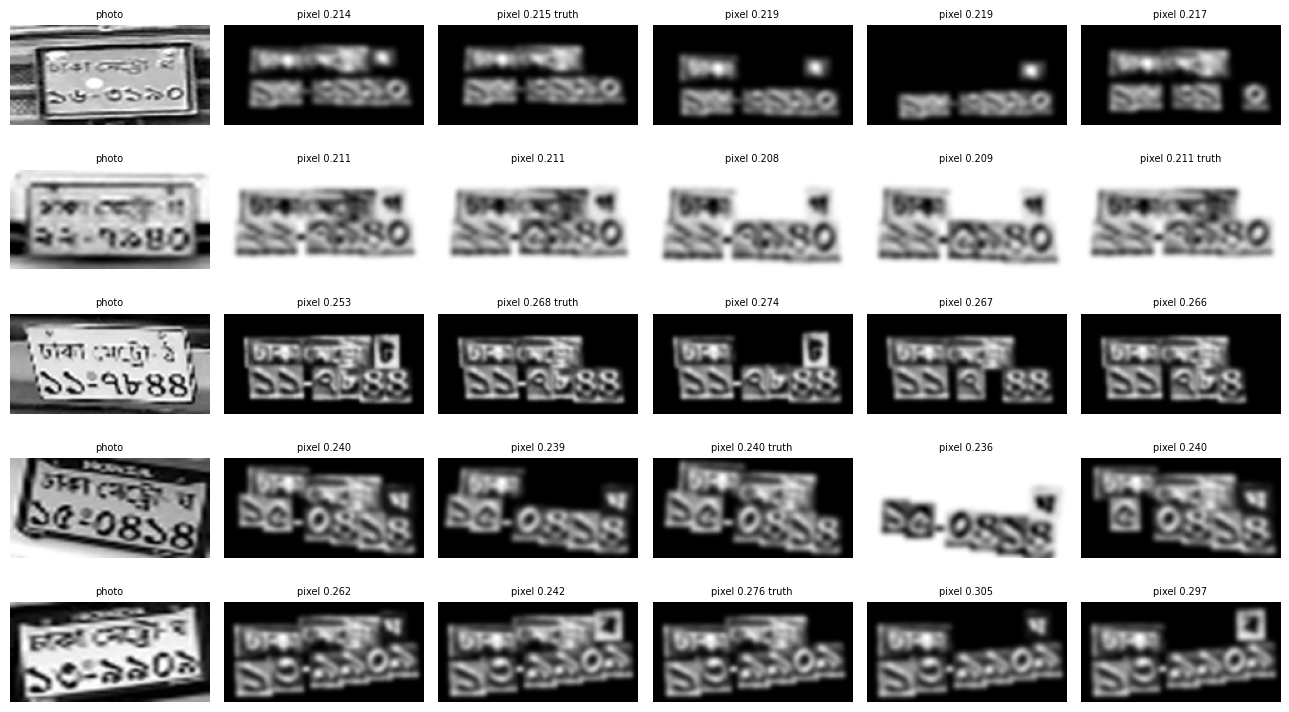

In [37]:
plates_by_name = {p["image"]: p for p in test_plates}
show = [plates_by_name[i] for i in list(fixed)[:5]]
if not show:
    # nothing fixed: show plates whose right reading was among the 5, to see why it was not chosen
    show = [p for p in test_plates if p["readings"] and p["readings"][0]["text"] != p["truth"]
            and any(r["text"] == p["truth"] for r in p["readings"])][:5]

if show:
    fig, axes = plt.subplots(len(show), 6, figsize=(13, 1.5 * len(show)), squeeze=False)
    for row, p in zip(axes, show):
        row[0].imshow(p["photo"][0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        row[0].set_title("photo", fontsize=7)
        for ax, img, r in zip(row[1:], p["fitted"], p["readings"]):
            ax.imshow(img[0].cpu(), cmap="gray")
            ax.set_title(f"{best} {r['dist'][best]:.3f}" + (" truth" if r["text"] == p["truth"] else ""), fontsize=7)
        for ax in row:
            ax.axis("off")
    plt.tight_layout()
    plt.savefig(WORK / "fit_examples.png", dpi=130)
    plt.show()
else:
    print("no plate to show")

## Save

Settings for the AI service and the demo. The atlas and the encoder were saved above.

In [38]:
config = {"PH": PH, "PW": PW, "GLYPH": GLYPH, "PAD": PAD, "STEPS": STEPS, "REG": REG, "FEAT_LAYER": FEAT_LAYER,
          "top_k": 5, "layout_lambda": best_lam, "layout_caps": CAP, "guess_conf": 0.05, "best_w": best_w, "best_score": best,
          "subset_limits": {k: float(v) for k, v in limits.items()}}
layout_table = [{"digits": l[0], "districts": l[1], "letters": l[2], "words": l[3], "plates": n}
                for l, n in layout_counts.items()]
(WORK / "plate_layouts.json").write_text(json.dumps(layout_table, indent=1))
(WORK / "redraw_config.json").write_text(json.dumps(config, indent=1))
print(json.dumps(config, indent=1))
print(sorted(p.name for p in WORK.iterdir()))

{
 "PH": 80,
 "PW": 160,
 "GLYPH": 48,
 "PAD": 0.08,
 "STEPS": 40,
 "REG": 0.5,
 "FEAT_LAYER": 4,
 "top_k": 5,
 "layout_lambda": 1.5,
 "layout_caps": {
  "digit": 8,
  "district": 1,
  "letter": 2,
  "word": 2
 },
 "guess_conf": 0.05,
 "best_w": {
  "pixel": 0,
  "edge": 0,
  "feature": 20,
  "learned": 0
 },
 "best_score": "pixel",
 "subset_limits": {
  "dark": 0.33241999745368955,
  "tilted": 9.95426056883492,
  "small": 416.0
 }
}
['.virtual_documents', '__pycache__', 'atlas.png', 'drawn_vs_photo.png', 'fit_examples.png', 'glyph_atlas.npz', 'plate_encoder.pt', 'plate_layers.py', 'plate_layouts.json', 'redraw_config.json', 'redraw_results.csv', 'redraw_test_plates.csv']
